In [1]:
#Task 1: Polynomial features (degree 2) for RAM and storage
import pandas as pd
from sklearn.preprocessing import PolynomialFeatures
from sklearn.metrics import mean_squared_error

ph = pd.read_csv("mobile_prices.csv")
X = ph[["ram", "storage"]]

pf = PolynomialFeatures(degree=2, include_bias=False)
Xp = pf.fit_transform(X)

print("Feature names:", list(pf.get_feature_names_out()))
print("Shape:", Xp.shape)
print("First 10 rows of the feature matrix:")
print(Xp[:10])

Feature names: ['ram', 'storage', 'ram^2', 'ram storage', 'storage^2']
Shape: (100, 5)
First 10 rows of the feature matrix:
[[3.0000e+00 6.4000e+01 9.0000e+00 1.9200e+02 4.0960e+03]
 [6.0000e+00 1.6000e+02 3.6000e+01 9.6000e+02 2.5600e+04]
 [4.0000e+00 9.6000e+01 1.6000e+01 3.8400e+02 9.2160e+03]
 [6.0000e+00 1.2800e+02 3.6000e+01 7.6800e+02 1.6384e+04]
 [1.2000e+01 2.8800e+02 1.4400e+02 3.4560e+03 8.2944e+04]
 [8.0000e+00 2.5600e+02 6.4000e+01 2.0480e+03 6.5536e+04]
 [2.0000e+00 3.2000e+01 4.0000e+00 6.4000e+01 1.0240e+03]
 [6.0000e+00 1.6000e+02 3.6000e+01 9.6000e+02 2.5600e+04]
 [8.0000e+00 2.5600e+02 6.4000e+01 2.0480e+03 6.5536e+04]
 [3.0000e+00 3.2000e+01 9.0000e+00 9.6000e+01 1.0240e+03]]


Linear MSE: 0.019
Polynomial MSE: 0.0139


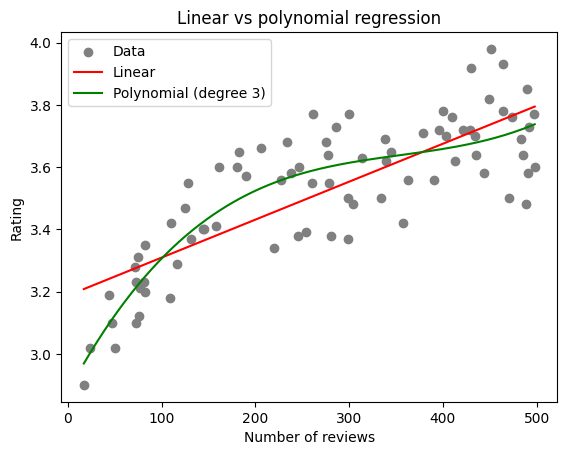

In [2]:
#Task 2: Linear vs polynomial (degree 3) regression for Zomato ratings
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression

zr = pd.read_csv("zomato_ratings.csv")
x = zr[["num_reviews"]].values
y = zr["rating"]

lin = LinearRegression()
lin.fit(x, y)

pf3 = PolynomialFeatures(degree=3)
poly = LinearRegression()
poly.fit(pf3.fit_transform(x), y)

print("Linear MSE:", round(mean_squared_error(y, lin.predict(x)), 4))
print("Polynomial MSE:", round(mean_squared_error(y, poly.predict(pf3.transform(x))), 4))

xs = np.linspace(x.min(), x.max(), 200).reshape(-1, 1)
plt.scatter(x, y, color="gray", label="Data")
plt.plot(xs, lin.predict(xs), color="red", label="Linear")
plt.plot(xs, poly.predict(pf3.transform(xs)), color="green", label="Polynomial (degree 3)")
plt.xlabel("Number of reviews")
plt.ylabel("Rating")
plt.title("Linear vs polynomial regression")
plt.legend()
plt.show()

# The straight line is too high for restaurants with few reviews and cannot follow the curve.
# The degree 3 curve rises fast at first and then flattens, which matches the data better, and its MSE is also lower.

Degree 1 -> train MSE: 778.24 validation MSE: 883.76
Degree 2 -> train MSE: 127.11 validation MSE: 376.4
Degree 3 -> train MSE: 103.14 validation MSE: 944.12
Degree 4 -> train MSE: 47.15 validation MSE: 41.64
Degree 5 -> train MSE: 45.48 validation MSE: 163.78


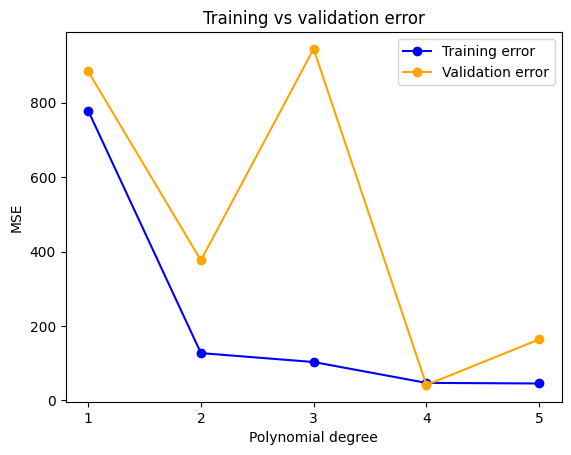


Degree 4 -> train MSE: 47.15 validation MSE: 41.64


In [3]:
#Task 3: Training and validation error for degrees 1 to 5 (Instagram followers vs posts)
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error

ig = pd.read_csv("instagram_users.csv")
xi = ig[["followers"]]
yi = ig["posts"]
xtr, xva, ytr, yva = train_test_split(xi, yi, test_size=0.3, random_state=2)

degs = [1, 2, 3, 4, 5]
tr_err = []
va_err = []
for d in degs:
    p = PolynomialFeatures(degree=d)
    m = LinearRegression()
    m.fit(p.fit_transform(xtr), ytr)
    tr_err.append(mean_squared_error(ytr, m.predict(p.transform(xtr))))
    va_err.append(mean_squared_error(yva, m.predict(p.transform(xva))))
    print("Degree", d, "-> train MSE:", round(tr_err[-1], 2), "validation MSE:", round(va_err[-1], 2))

plt.plot(degs, tr_err, marker="o", color="blue", label="Training error")
plt.plot(degs, va_err, marker="o", color="orange", label="Validation error")
plt.xlabel("Polynomial degree")
plt.ylabel("MSE")
plt.title("Training vs validation error")
plt.xticks(degs)
plt.legend()
plt.show()

# degree 4 model as asked in the task
p4 = PolynomialFeatures(degree=4)
m4 = LinearRegression()
m4.fit(p4.fit_transform(xtr), ytr)
print("\nDegree 4 -> train MSE:", round(mean_squared_error(ytr, m4.predict(p4.transform(xtr))), 2),
      "validation MSE:", round(mean_squared_error(yva, m4.predict(p4.transform(xva))), 2))

# Degrees 1 to 3 are underfitting or unstable, since both errors are high.
# Degree 4 gives the lowest validation error (about 42), so it is the best choice here.
# At degree 5 the training error hardly changes but the validation error goes up to about 164, so the model starts to overfit.

In [4]:
#Task 4: Polynomial regression (degree 3) with and without Ridge on Flipkart prices
from sklearn.linear_model import Ridge
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

fk = pd.read_csv("flipkart_prices.csv")
xf = fk[["mrp", "discount", "rating"]]
yf = fk["price"]
xtr, xte, ytr, yte = train_test_split(xf, yf, test_size=0.3, random_state=3)

plain = make_pipeline(PolynomialFeatures(3), StandardScaler(), LinearRegression())
ridge = make_pipeline(PolynomialFeatures(3), StandardScaler(), Ridge(alpha=100))
plain.fit(xtr, ytr)
ridge.fit(xtr, ytr)

print("Without Ridge -> train MSE:", round(mean_squared_error(ytr, plain.predict(xtr)), 1),
      "test MSE:", round(mean_squared_error(yte, plain.predict(xte)), 1))
print("With Ridge    -> train MSE:", round(mean_squared_error(ytr, ridge.predict(xtr)), 1),
      "test MSE:", round(mean_squared_error(yte, ridge.predict(xte)), 1))

# With Ridge the train error is higher but the test error is lower (about 320000 against 387000 without Ridge).
# A degree 3 model has many terms and without regularization it fits the noise in the training data.
# Ridge keeps the coefficients small, so the model is less sensitive to noise and does better on new data.

Without Ridge -> train MSE: 10711.0 test MSE: 387125.9
With Ridge    -> train MSE: 252419.8 test MSE: 320686.1


Degree 1 -> train MSE: 0.345 test MSE: 0.287
Degree 4 -> train MSE: 0.099 test MSE: 0.075
Degree 15 -> train MSE: 0.052 test MSE: 25.728


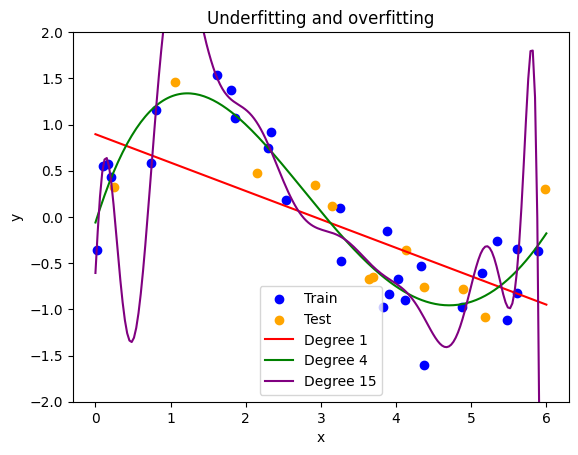

In [5]:
#Task 5: Underfitting and overfitting with polynomial regression on synthetic data
rng = np.random.default_rng(0)
xs_all = np.sort(rng.uniform(0, 6, 40)).reshape(-1, 1)
ys_all = np.sin(xs_all).ravel() + rng.normal(0, 0.3, 40)
xtr, xte, ytr, yte = train_test_split(xs_all, ys_all, test_size=0.3, random_state=4)

grid = np.linspace(0, 6, 200).reshape(-1, 1)
plt.scatter(xtr, ytr, color="blue", label="Train")
plt.scatter(xte, yte, color="orange", label="Test")

for d, col in [(1, "red"), (4, "green"), (15, "purple")]:
    m = make_pipeline(PolynomialFeatures(d), StandardScaler(), LinearRegression())
    m.fit(xtr, ytr)
    tr = mean_squared_error(ytr, m.predict(xtr))
    te = mean_squared_error(yte, m.predict(xte))
    print("Degree", d, "-> train MSE:", round(tr, 3), "test MSE:", round(te, 3))
    plt.plot(grid, m.predict(grid), color=col, label="Degree " + str(d))

plt.ylim(-2, 2)
plt.xlabel("x")
plt.ylabel("y")
plt.title("Underfitting and overfitting")
plt.legend()
plt.show()

# Degree 1 is too simple. A straight line cannot follow the curve, so the error is high (underfitting, high bias).
# Degree 4 follows the curve well and has low error on both train and test data.
# Degree 15 is too flexible. Its train error is very low but its test error is huge because it fits the noise (overfitting, high variance).
# So a low degree gives high bias and low variance, a very high degree gives low bias and high variance, and a middle degree works best.